# 03_train_convnext_tiny.ipynb

Fine-tune ConvNeXt-Tiny trên DurianLDD. Checkpoint chọn bằng macro F1 của validation. Notebook chạy trên Kaggle với GPU.

Cell môi trường kéo nhánh `baseline-ConvNeXt-Tiny` và gắn ảnh từ `cthng123/durian-leaf-disease-dataset`. Split lấy từ `manifests/split_manifest.csv`. Tập test không mở.

## 1. Môi trường

Internet để On. Accelerator chọn GPU. Dataset input là `cthng123/durian-leaf-disease-dataset`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "baseline-ConvNeXt-Tiny"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: baseline-ConvNeXt-Tiny
Commit: 7f2230b
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Dữ liệu và cấu hình

Ảnh đọc từ dataset Kaggle. Tập train và validation đọc từ cột `split` của manifest.

In [2]:
from src.training.run import load_configs, prepare_loaders

CONFIG = "configs/train_convnext_tiny.yaml"
train_cfg, pipeline_cfg = load_configs(CONFIG)
device, loaders = prepare_loaders(pipeline_cfg)

print(f"Thiết bị: {device}")
print(f"Seed: {pipeline_cfg['seed']}")
print(f"Ảnh train: {len(loaders['train'].dataset)}")
print(f"Ảnh validation: {len(loaders['val'].dataset)}")
print(f"Batch size: {pipeline_cfg['batch_size']}")
print(f"Optimizer: {train_cfg['optimizer']}")
print(f"Learning rate: {train_cfg['learning_rate']}")
print(f"Scheduler: {train_cfg['scheduler']}")
print(f"Epoch tối đa: {train_cfg['epochs']}")
print(f"Patience: {train_cfg['patience']}")
print("Tập test: không mở")

Thiết bị: cuda
Seed: 42
Ảnh train: 3105
Ảnh validation: 444
Batch size: 32
Optimizer: adamw
Learning rate: 0.0002
Scheduler: cosine
Epoch tối đa: 30
Patience: 7
Tập test: không mở


## 3. Model

ConvNeXt-Tiny từ timm, trọng số ImageNet, fine-tune toàn bộ mạng, 5 lớp.

In [3]:
from src.models.build import build_model
from src.training.loop import trainable_parameter_count

model = build_model(train_cfg, num_classes=int(pipeline_cfg["num_classes"]))
print(f"Backbone: {train_cfg['library']} {train_cfg['backbone']}")
print(f"Số tham số: {trainable_parameter_count(model)}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone: timm convnext_tiny
Số tham số: 27823973


## 4. Train

Mỗi epoch in loss, macro F1 và balanced accuracy trên validation. Dòng có chữ `checkpoint` là epoch đang được giữ.

In [4]:
from src.training.loop import fit_model

result = fit_model(
    model=model,
    train_loader=loaders["train"],
    val_loader=loaders["val"],
    class_names=list(pipeline_cfg["classes"]),
    train_cfg=train_cfg,
    device=device,
)
print(f"Epoch được chọn: {result['best_epoch']}")
print(f"Thời gian train (giây): {result['elapsed_seconds']:.1f}")

Epoch 01/30  train_loss=1.6777  val_loss=1.6107  val_macro_f1=0.0687  val_balanced_accuracy=0.2000  515.3s  checkpoint
Epoch 02/30  train_loss=1.6134  val_loss=1.4995  val_macro_f1=0.1969  val_balanced_accuracy=0.3236  89.2s  checkpoint
Epoch 03/30  train_loss=1.4845  val_loss=1.5124  val_macro_f1=0.2525  val_balanced_accuracy=0.3301  88.9s  checkpoint
Epoch 04/30  train_loss=1.4564  val_loss=1.3933  val_macro_f1=0.3697  val_balanced_accuracy=0.3884  89.3s  checkpoint
Epoch 05/30  train_loss=1.3959  val_loss=1.5652  val_macro_f1=0.3204  val_balanced_accuracy=0.3365  89.5s
Epoch 06/30  train_loss=1.3486  val_loss=1.2828  val_macro_f1=0.4676  val_balanced_accuracy=0.4720  89.4s  checkpoint
Epoch 07/30  train_loss=1.2272  val_loss=1.1765  val_macro_f1=0.5036  val_balanced_accuracy=0.5063  89.5s  checkpoint
Epoch 08/30  train_loss=1.0927  val_loss=0.9161  val_macro_f1=0.6383  val_balanced_accuracy=0.6395  89.3s  checkpoint
Epoch 09/30  train_loss=1.0169  val_loss=1.1157  val_macro_f1=0.526

## 5. Kết quả validation

Macro F1 là metric chọn checkpoint. Balanced accuracy, recall từng lớp và confusion matrix đi cùng checkpoint đó.

Thiết bị: Tesla T4
Thời gian train (giây): 3109.2
Số tham số: 27823973
Epoch được chọn: 24
Val macro F1: 0.9775
Val balanced accuracy: 0.9775
Val loss: 0.1173
Recall từng lớp:
  ALGAL_LEAF_SPOT: 0.9730
  ALLOCARIDARA_ATTACK: 0.9891
  HEALTHY_LEAF: 0.9794
  LEAF_BLIGHT: 0.9462
  PHOMOPSIS_LEAF_SPOT: 1.0000
Checkpoint: /kaggle/working/durian-leaf-disease-robustness/outputs/checkpoints/convnext_tiny_seed42.pt
Metric: /kaggle/working/durian-leaf-disease-robustness/outputs/results/convnext_tiny_seed42.json
Confusion matrix: /kaggle/working/durian-leaf-disease-robustness/outputs/results/convnext_tiny_seed42_confusion_matrix.png
History: /kaggle/working/durian-leaf-disease-robustness/outputs/results/convnext_tiny_seed42_history.png


,best_epoch,val_macro_f1,val_balanced_accuracy,val_loss,parameters,seconds
0,24,0.977461,0.977544,0.117275,27823973,3109.2


,class_name,recall
0,ALGAL_LEAF_SPOT,0.972973
1,ALLOCARIDARA_ATTACK,0.989130
2,HEALTHY_LEAF,0.979381
3,LEAF_BLIGHT,0.946237
4,PHOMOPSIS_LEAF_SPOT,1.000000


,epoch,lr,train_loss,train_accuracy,val_loss,val_macro_f1,val_balanced_accuracy,seconds
0,1,2.000000e-04,1.677733,0.208374,1.610670,0.068657,0.200000,515.309974
1,2,1.994522e-04,1.613410,0.230274,1.499502,0.196920,0.323559,89.223907
2,3,1.978148e-04,1.484527,0.314010,1.512377,0.252528,0.330067,88.947546
3,4,1.951057e-04,1.456448,0.343961,1.393298,0.369738,0.388370,89.340361
4,5,1.913545e-04,1.395856,0.390338,1.565208,0.320387,0.336450,89.455183
5,6,1.866025e-04,1.348594,0.431240,1.282792,0.467645,0.471995,89.420515
6,7,1.809017e-04,1.227221,0.503704,1.176503,0.503587,0.506349,89.518447
7,8,1.743145e-04,1.092743,0.561353,0.916066,0.638332,0.639519,89.278969
8,9,1.669131e-04,1.016941,0.603543,1.115699,0.526397,0.574891,89.802340
9,10,1.587785e-04,0.661131,0.746538,0.529269,0.820782,0.813985,89.584816


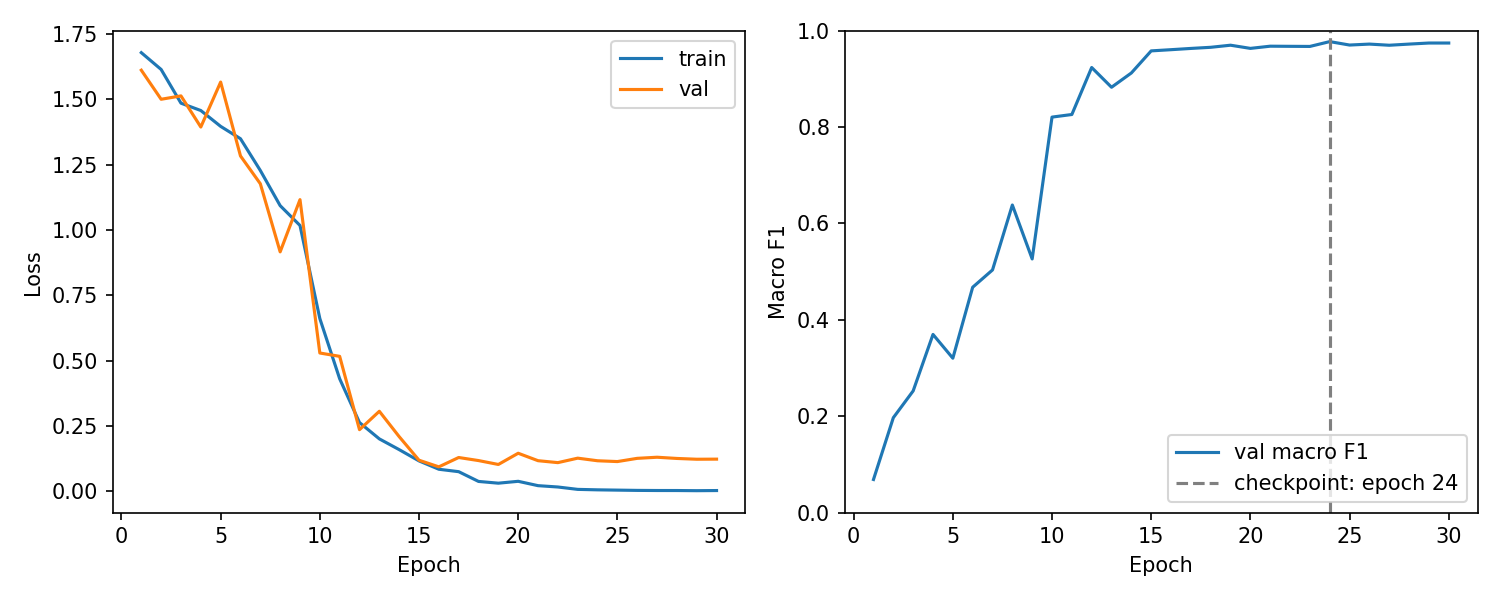

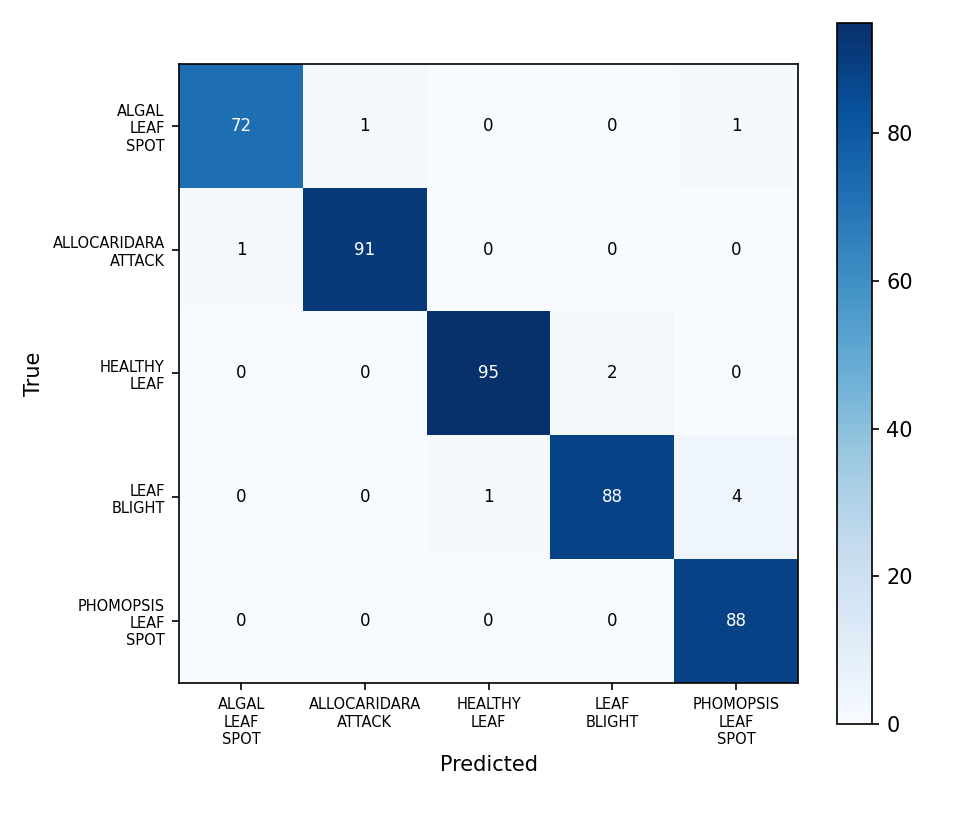

In [5]:
import pandas as pd
from IPython.display import Image, display

from src.training.run import ROOT, print_run_report, resource_name, save_run_artifacts

paths = save_run_artifacts(result, pipeline_cfg, train_cfg, device, ROOT / "outputs")
print_run_report(result, paths, resource_name(device))

best = result["best_val"]
display(pd.DataFrame([
    {
        "best_epoch": result["best_epoch"],
        "val_macro_f1": best["macro_f1"],
        "val_balanced_accuracy": best["balanced_accuracy"],
        "val_loss": best["loss"],
        "parameters": result["trainable_parameters"],
        "seconds": round(result["elapsed_seconds"], 1),
    }
]))
display(pd.DataFrame(
    [{"class_name": name, "recall": value} for name, value in best["per_class_recall"].items()]
))
display(pd.DataFrame(result["history"]))
display(Image(filename=paths["history"]))
display(Image(filename=paths["confusion_matrix"]))